<img src="../shared/alchemi-banner-left.png" alt="NVIDIA ALCHEMI: AI for Chemistry and Materials Science" style="display:block;box-sizing:border-box;width:100%;max-width:100%;height:auto;">

<style>
h1 {
  font-size: 2.35rem !important;
  line-height: 1.15 !important;
  margin: 0.7rem 0 1rem !important;
}
h2 {
  font-size: 1.9rem !important;
  line-height: 1.2 !important;
  margin: 0.6rem 0 1rem !important;
}
h3 {
  font-size: 1.35rem !important;
  line-height: 1.3 !important;
  margin: 1.9rem 0 0.75rem !important;
}
h4 {
  font-size: 1.08rem !important;
  line-height: 1.35 !important;
  margin: 1.35rem 0 0.65rem !important;
}
.alchemi-api-label,
span[aria-label="ALCHEMI Toolkit API"] {
  color: currentColor !important;
  font-size: 0.70rem !important;
  font-weight: 700;
  letter-spacing: 0.05em;
}
@supports (color: color-mix(in srgb, black, white)) {
  .alchemi-api-label,
  span[aria-label="ALCHEMI Toolkit API"] {
    color: color-mix(in srgb, currentColor 68%, #76B900 32%) !important;
  }
}
</style>

# ALCHEMI Core · Module 02: Simulate and compose

**Goal:** Compose AIMNet2, dispersion, and electrostatics; run hot NCI trajectories; and keep weak complexes together with a bias hook.

**Estimated time:** 40 minutes  
**Next module:** [Module 03: Scale a study →](alchemi-core-03-scale-a-study.ipynb)

<img src="assets/course-roadmap-module02.svg" alt="ALCHEMI Core roadmap with Compose models highlighted in Module 02" style="display:block;box-sizing:border-box;width:100%;max-width:920px;height:auto;margin:1rem 0 0;">

Module 01 built `AtomicData` and `Batch`. Here, those same objects move through composed models and molecular dynamics.

In [ ]:
# Import the scientific Python, course-helper, and Toolkit APIs used below.
import random
import warnings

# Filter the PhysicsNeMo 2.1.1 Python 3.12 regex warning during imports.
warnings.filterwarnings(
    "ignore",
    message=r"invalid escape sequence '\\\.'",
    category=SyntaxWarning,
)

import torch
from ase.units import kcal, mol
from IPython.display import display
from helpers import module02 as helpers
from nvalchemi.data import AtomicData, Batch
from nvalchemi.dynamics import DynamicsStage, HostMemory, NVTLangevin
from nvalchemi.dynamics import initialize_velocities
from nvalchemi.dynamics.hooks import NaNDetectorHook, SnapshotHook
from nvalchemi.hooks import BiasedPotentialHook, DynamicsContext
from nvalchemi.models import AIMNet2Wrapper, DFTD3ModelWrapper, PipelineGroup
from nvalchemi.models import PipelineModelWrapper, PipelineStep
from nvalchemi.neighbors import compute_neighbors

In [2]:
# Apply the shared notebook display and plotting defaults.
helpers.configure_tutorial()

# Keep every model and Batch on CUDA when a GPU is available.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("device:", device)
if device.type == "cuda":
    print("gpu:   ", torch.cuda.get_device_name(device))

device: cuda
gpu:    NVIDIA RTX 4000 SFF Ada Generation


## 1 · See how a well-composed Toolkit model reaches near-gold-standard accuracy

Intermolecular interactions drive molecular recognition, solvation, crystal packing, and adsorption. Even advanced MLIPs such as AIMNet2 benefit from explicit physical terms for these weak interactions.

Each panel follows one molecular pair as its separation changes. The curves show bare AIMNet2, AIMNet2 + D3 dispersion, and AIMNet2 + D3 + electrostatics against CCSD(T)/CBS. 

*Each interaction energy is `E(AB) - E(A) - E(B)` in kcal/mol. More negative values mean stronger attraction.*

In [3]:
# Load 90 frozen AB/A/B structures, aligned row metadata, and 30 references.
nci_atoms, nci_rows, nci_references = helpers.load_nci_atlas()
# Use the saved model curves for this result-first preview.
nci_curves = helpers.checked_nci_interaction_curves(nci_references)

print("scan points total     ", len(nci_curves))
print("AB/A/B structures    ", len(nci_atoms))

scan points total      30
AB/A/B structures     90



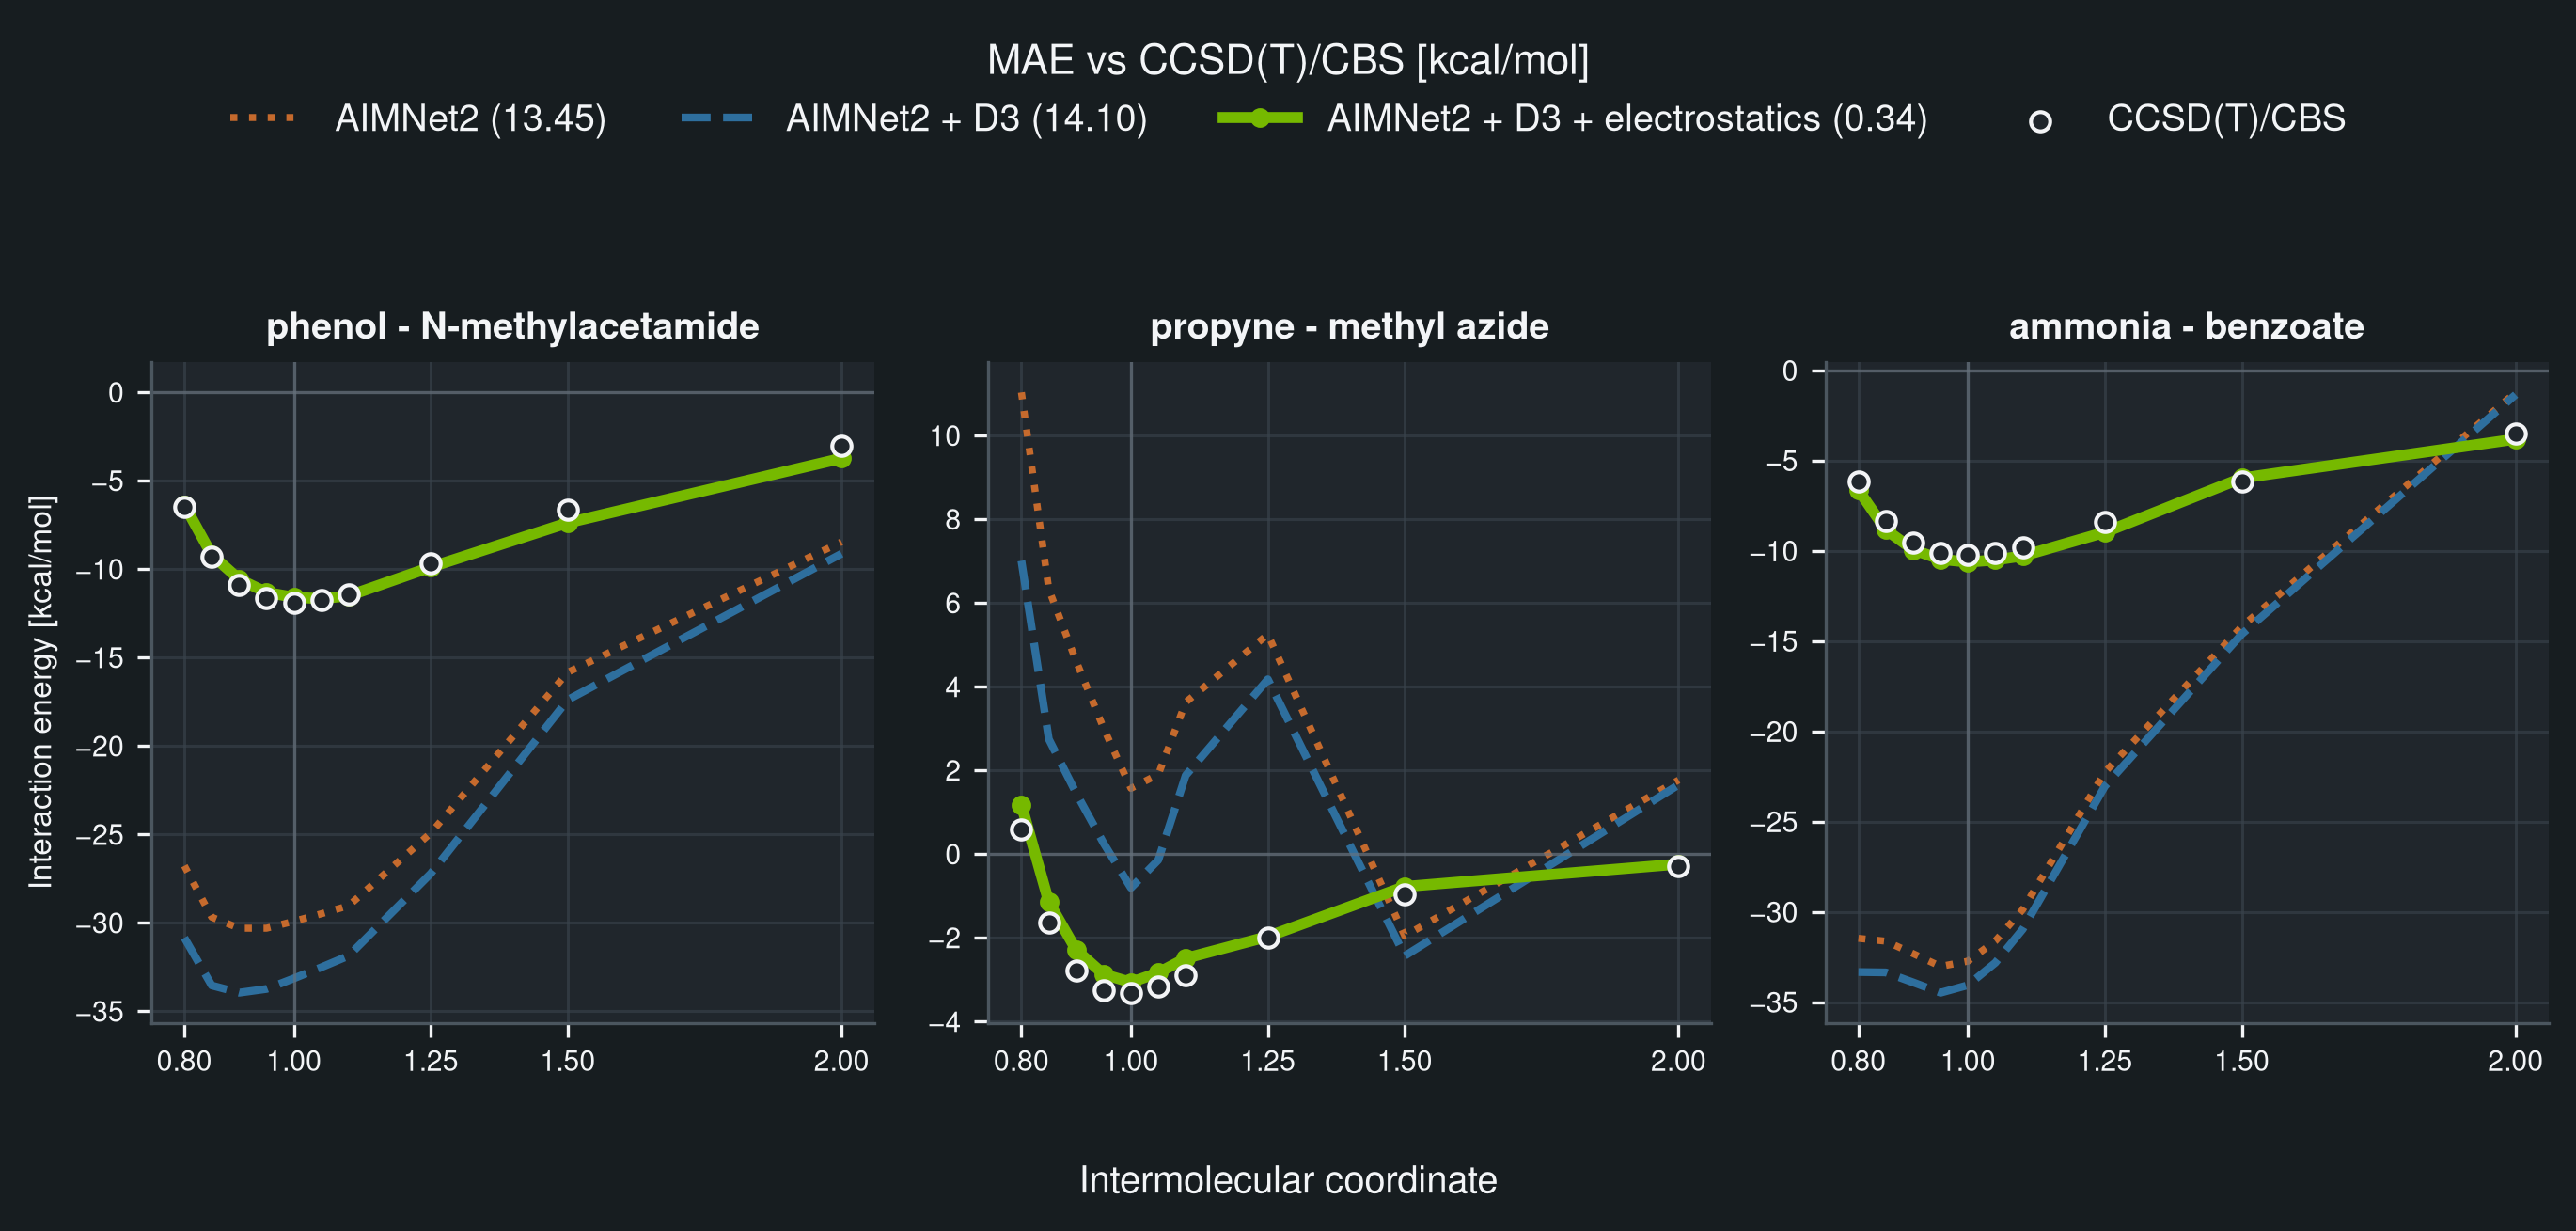

In [5]:
# Plot the three model routes against the CCSD(T)/CBS references.
helpers.plot_nci_interaction_curves(nci_curves, nci_references)

The molecular geometries come from the [NCI Atlas](https://github.com/Honza-R/NCIAtlas), a high-quality collection of intermolecular interaction data.

The player moves through all three separation scans together. Each card shows the closest intermolecular distance `d_min` and its change from equilibrium `Δd_min`; the dotted line marks that atom pair.

In [ ]:
# Group the ten AB geometries for each complex and record its A/B boundary.
scan_trajectories, scan_fragment_sizes, scan_scales = helpers.nci_scan_player_data(nci_atoms, nci_rows)

# Build one player that keeps all three complexes on the same dataset scan point.
helpers.show_nci_separation_player(scan_trajectories, scan_fragment_sizes, scan_scales)

> **Bottom line**
>
> D3 and electrostatics are essential to capture intermolecular interactions. Toolkit lets us compose both terms and pass the complete model into the same simulation API.

**🔗 Learn more in Toolkit docs**

- [Models and model composition](https://nvidia.github.io/nvalchemi-toolkit/userguide/models.html#composing-multiple-models) - Choose between additive and dependent composition.
- [AIMNet2 electrostatics pipeline](https://nvidia.github.io/nvalchemi-toolkit/examples/advanced/08_aimnet2_ewald_pipeline.html) - Follow predicted charges into electrostatics with autograd.

<hr class="alchemi-section-divider" aria-hidden="true" style="border:0;border-top:1px solid #D6D9D4;margin:2.4rem 0 1rem;">

## 2 · Compose the interaction model

We will rebuild all three curves from the same 90 frozen structures. As in Module 1, each ASE structure becomes one `AtomicData` object and `Batch` packs the independent structures on one device. Construction, execution, and inspection stay separate so each Toolkit action is visible.

In [7]:
# Convert every AB complex and isolated fragment to one AtomicData object.
nci_scan_data = [
    AtomicData.from_atoms(atoms, device=device)
    for atoms in nci_atoms
]

# Batch packs all 90 structures for one model call on the selected device.
nci_scan_batch = Batch.from_data_list(nci_scan_data, device=device)
print("molecular structures:", nci_scan_batch.num_graphs)
print("atoms:", nci_scan_batch.num_nodes)

molecular structures: 90
atoms: 1140


### Load a built-in model wrapper

Toolkit includes built-in model wrappers, so supported pretrained models are ready to use with the same data and simulation APIs. A wrapper handles model-specific checkpoint loading and adapts native inputs and outputs to Toolkit's common model interface. The wrapped model accepts `AtomicData` and `Batch`, joins a model pipeline, and can drive Toolkit dynamics.

`AIMNet2Wrapper` is Toolkit's built-in wrapper for AIMNet2. `from_checkpoint(...)` accepts either a checkpoint path or a model alias from the AIMNet registry. Here we pass the pinned `"aimnet2-wb97m-d3_0"` alias directly. The runtime setup prepares and verifies that checkpoint, and the wrapper loads its FP32 model onto `device`.

See the [AIMNet2 model card](https://huggingface.co/isayevlab/aimnet2-wb97m-d3) and [AIMNetCentral source and MIT license](https://github.com/isayevlab/aimnetcentral) for the checkpoint scope and reuse terms.

> <span aria-label="ALCHEMI Toolkit API" class="alchemi-api-label">&lt;/&gt;&nbsp; API</span>
>
> `AIMNet2Wrapper.from_checkpoint("aimnet2-wb97m-d3_0", device=device)`
>
> **Input:** an AIMNet2 checkpoint path or registry alias and a target device  
> **Returns:** a ready-to-call FP32 AIMNet2 model with Toolkit's common interface

The separate `aimnet.eval()` call selects evaluation behavior in its PyTorch modules. Autograd remains available when a later calculation requests force derivatives.

In [8]:
aimnet = AIMNet2Wrapper.from_checkpoint(
    "aimnet2-wb97m-d3_0",
    device=device,
)
aimnet.eval()

AIMNet2Wrapper(
  outputs={charges, energy, forces, stress}
  active_outputs={charges, energy, forces}
  autograd_outputs={forces, stress}
  required_inputs={charge}
  optional_inputs={cell, mult}
  pbc=[supports_pbc]
  neighbors=(cutoff=5.0, format=matrix)
  (model): AIMNet2(
    (aev): AEVSV()
    (afv): Embedding(64, 16, padding_idx=0)
    (conv_a): ConvSV()
    (conv_q): ConvSV()
    (mlps): ModuleList(
      (0): Sequential(
        (0): Linear(in_features=704, out_features=512, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=512, out_features=380, bias=True)
        (3): GELU(approximate='none')
        (4): Linear(in_features=380, out_features=258, bias=True)
      )
      (1): Sequential(
        (0): Linear(in_features=733, out_features=512, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=512, out_features=380, bias=True)
        (3): GELU(approximate='none')
        (4): Linear(in_features=380, out_features=258

In [9]:
# Request one energy per structure and one predicted charge per atom.
aimnet.set_config("active_outputs", {"energy", "charges"})

In [10]:
# Inspect the configured model interface before its first call.
print("required inputs:", aimnet.input_data())
print("active outputs:", aimnet.model_config.active_outputs)
print("neighbor configuration:", aimnet.model_config.neighbor_config)

required inputs: {'atomic_numbers', 'positions', 'charge', 'neighbor_matrix', 'num_neighbors'}
active outputs: {'energy', 'charges'}
neighbor configuration: cutoff=5.0 format=<NeighborListFormat.MATRIX: 'matrix'> half_list=False skin=0.0


### Build the model's neighbor list

AIMNet2 evaluates local atom pairs, so it needs a neighbor list in addition to positions and elements. `compute_neighbors(...)` writes those pairs into the `Batch` in place using the model's own `neighbor_config`. We prepare a clone so the shared scan batch remains available for the other model routes.

Calling the wrapper as `aimnet(batch)` returns a dictionary keyed by the requested outputs. This example reads the system-level `energy` and atom-level `charges` tensors.

> <span aria-label="ALCHEMI Toolkit API" class="alchemi-api-label">&lt;/&gt;&nbsp; API</span>
>
> `compute_neighbors(batch, config=model.model_config.neighbor_config)`
>
> **Input:** a `Batch` and the model's neighbor configuration  
> **Effect:** writes the neighbor list required by the next forward call

In [11]:
aimnet_batch = nci_scan_batch.clone()
compute_neighbors(
    aimnet_batch,
    config=aimnet.model_config.neighbor_config,
)  # Write AIMNet2's neighbor list into this clone.
aimnet_output = aimnet(aimnet_batch)

print("energy shape:", tuple(aimnet_output["energy"].shape))
print("charge shape:", tuple(aimnet_output["charges"].shape))
print("output device:", aimnet_output["energy"].device)

energy shape: (90, 1)
charge shape: (1140,)
output device: cuda:0


### Add explicit D3 dispersion

`DFTD3ModelWrapper` takes the AIMNet2 D3(BJ) coefficients `a1`, `a2`, and `s8`. Here `a1` and `s8` are dimensionless, `a2` is in Bohr, and `cutoff` is in Å.

`param_file` points to the D3 element-reference table installed with the course. The wrapper loads it when the model is created.

> <span aria-label="ALCHEMI Toolkit API" class="alchemi-api-label">&lt;/&gt;&nbsp; API</span>
>
> `DFTD3ModelWrapper(a1=..., a2=..., s8=..., cutoff=..., param_file=...)`
>
> **Input:** D3(BJ) damping coefficients, a neighbor cutoff, and the element-reference table  
> **Returns:** a Toolkit model wrapper that computes D3 energy and requested derivatives

In [12]:
d3_parameter_file = helpers.d3_parameter_file()
d3 = DFTD3ModelWrapper(
    a1=0.566,     # Dimensionless BJ damping coefficient
    a2=3.128,     # BJ damping length [Bohr]
    s8=0.3908,    # Dimensionless C8 scale
    cutoff=15.0,  # Neighbor cutoff [Å]
    param_file=d3_parameter_file,
)
d3.to(device)
d3.eval()
d3.set_config("active_outputs", {"energy"})

#### Run D3 on the same structures

The D3 wrapper has its own neighbor configuration. Build those neighbors, run one forward call, and inspect the system-level energy tensor.

In [13]:
d3_batch = nci_scan_batch.clone()
compute_neighbors(d3_batch, config=d3.model_config.neighbor_config)
d3_output = d3(d3_batch)

print("D3 energy shape:", tuple(d3_output["energy"].shape))
print("D3 output device:", d3_output["energy"].device)

D3 energy shape: (90, 1)
D3 output device: cuda:0


### Add D3 as an independent pipeline group

A `PipelineModelWrapper` owns one or more `PipelineGroup` objects and exposes their combined outputs through Toolkit's common model interface. Each group below contains one independent model: AIMNet2 or D3. Its `steps` define what runs within that group, and `use_autograd=False` lets each model return its own energy for the wrapper to add.

`neighbor_adaptation="always"` builds one source neighbor list at the largest cutoff and filters it for the model with the smaller cutoff. After the forward call, we will subtract bare AIMNet2 and check that the combined energy added by this wrapper is the direct D3 energy.

In [14]:
# Each independent group returns its own energy contribution.
aimnet_group = PipelineGroup(steps=[aimnet], use_autograd=False)
d3_group = PipelineGroup(steps=[d3], use_autograd=False)

aimnet_d3 = PipelineModelWrapper(
    groups=[aimnet_group, d3_group],
    neighbor_adaptation="always",
)
aimnet_d3.to(device)
aimnet_d3.eval()
aimnet_d3.set_config("active_outputs", {"energy"})

In [ ]:
# Copy the 90 structures, then attach a fresh shared neighbor list.
aimnet_d3_batch = nci_scan_batch.clone()
compute_neighbors(
    aimnet_d3_batch,
    config=aimnet_d3.model_config.neighbor_config)
# Run AIMNet2 and D3; the wrapper adapts the list and sums their energies.
aimnet_d3_output = aimnet_d3(aimnet_d3_batch)

#### Check the energy added by the pipeline

The AIMNet2 and D3 groups are independent, so the wrapper adds their energies. Subtracting bare AIMNet2 from the pipeline result should therefore recover the direct D3 energy.

The next cell shows the D3 energy of the AB complex and its isolated A and B fragments for the first scan point, once from each route. It then reports the maximum absolute difference across all 90 structures. The following interaction plot evaluates model accuracy against CCSD(T)/CBS.

In [16]:
# Subtract bare AIMNet2 to recover the D3 energy added by the pipeline.
pipeline_d3_energy = aimnet_d3_output["energy"] - aimnet_output["energy"]
direct_d3_energy = d3_output["energy"]

# The first three rows are the AB complex and its isolated A and B fragments.
print("order: AB complex, fragment A, fragment B")
print("pipeline D3 [eV]:", pipeline_d3_energy[:3, 0].tolist())
print("direct D3 [eV]:", direct_d3_energy[:3, 0].tolist())

d3_difference = (pipeline_d3_energy - direct_d3_energy).abs()
print("maximum absolute difference [eV]:", d3_difference.max().item())

order: AB complex, fragment A, fragment B
pipeline D3 [eV]: [-1.0202744007110596, -0.49504881980465143, -0.34880369901657104]
direct D3 [eV]: [-1.0202744007110596, -0.495048463344574, -0.34880369901657104]
maximum absolute difference [eV]: 0.0019522653383319266


In [17]:
# Reshape the flat outputs into [scan points, AB/A/B].
aimnet_by_scan = aimnet_output["energy"].reshape(-1, 3)
aimnet_d3_by_scan = aimnet_d3_output["energy"].reshape(-1, 3)

# Calculate E(AB) - E(A) - E(B), then convert eV to kcal/mol.
aimnet_interactions = aimnet_by_scan[:, 0] - aimnet_by_scan[:, 1] - aimnet_by_scan[:, 2]
aimnet_d3_interactions = aimnet_d3_by_scan[:, 0] - aimnet_d3_by_scan[:, 1]
aimnet_d3_interactions = aimnet_d3_interactions - aimnet_d3_by_scan[:, 2]

aimnet_interactions = aimnet_interactions * mol / kcal
aimnet_d3_interactions = aimnet_d3_interactions * mol / kcal
aimnet_interactions = aimnet_interactions.detach().cpu()
aimnet_d3_interactions = aimnet_d3_interactions.detach().cpu()

# Store the calculated interaction energies beside the aligned scan metadata.
d3_curves = nci_references.drop(columns="ccsd_t_cbs_kcal_mol").copy()
d3_curves["aimnet_base"] = aimnet_interactions.numpy()
d3_curves["base_d3"] = aimnet_d3_interactions.numpy()


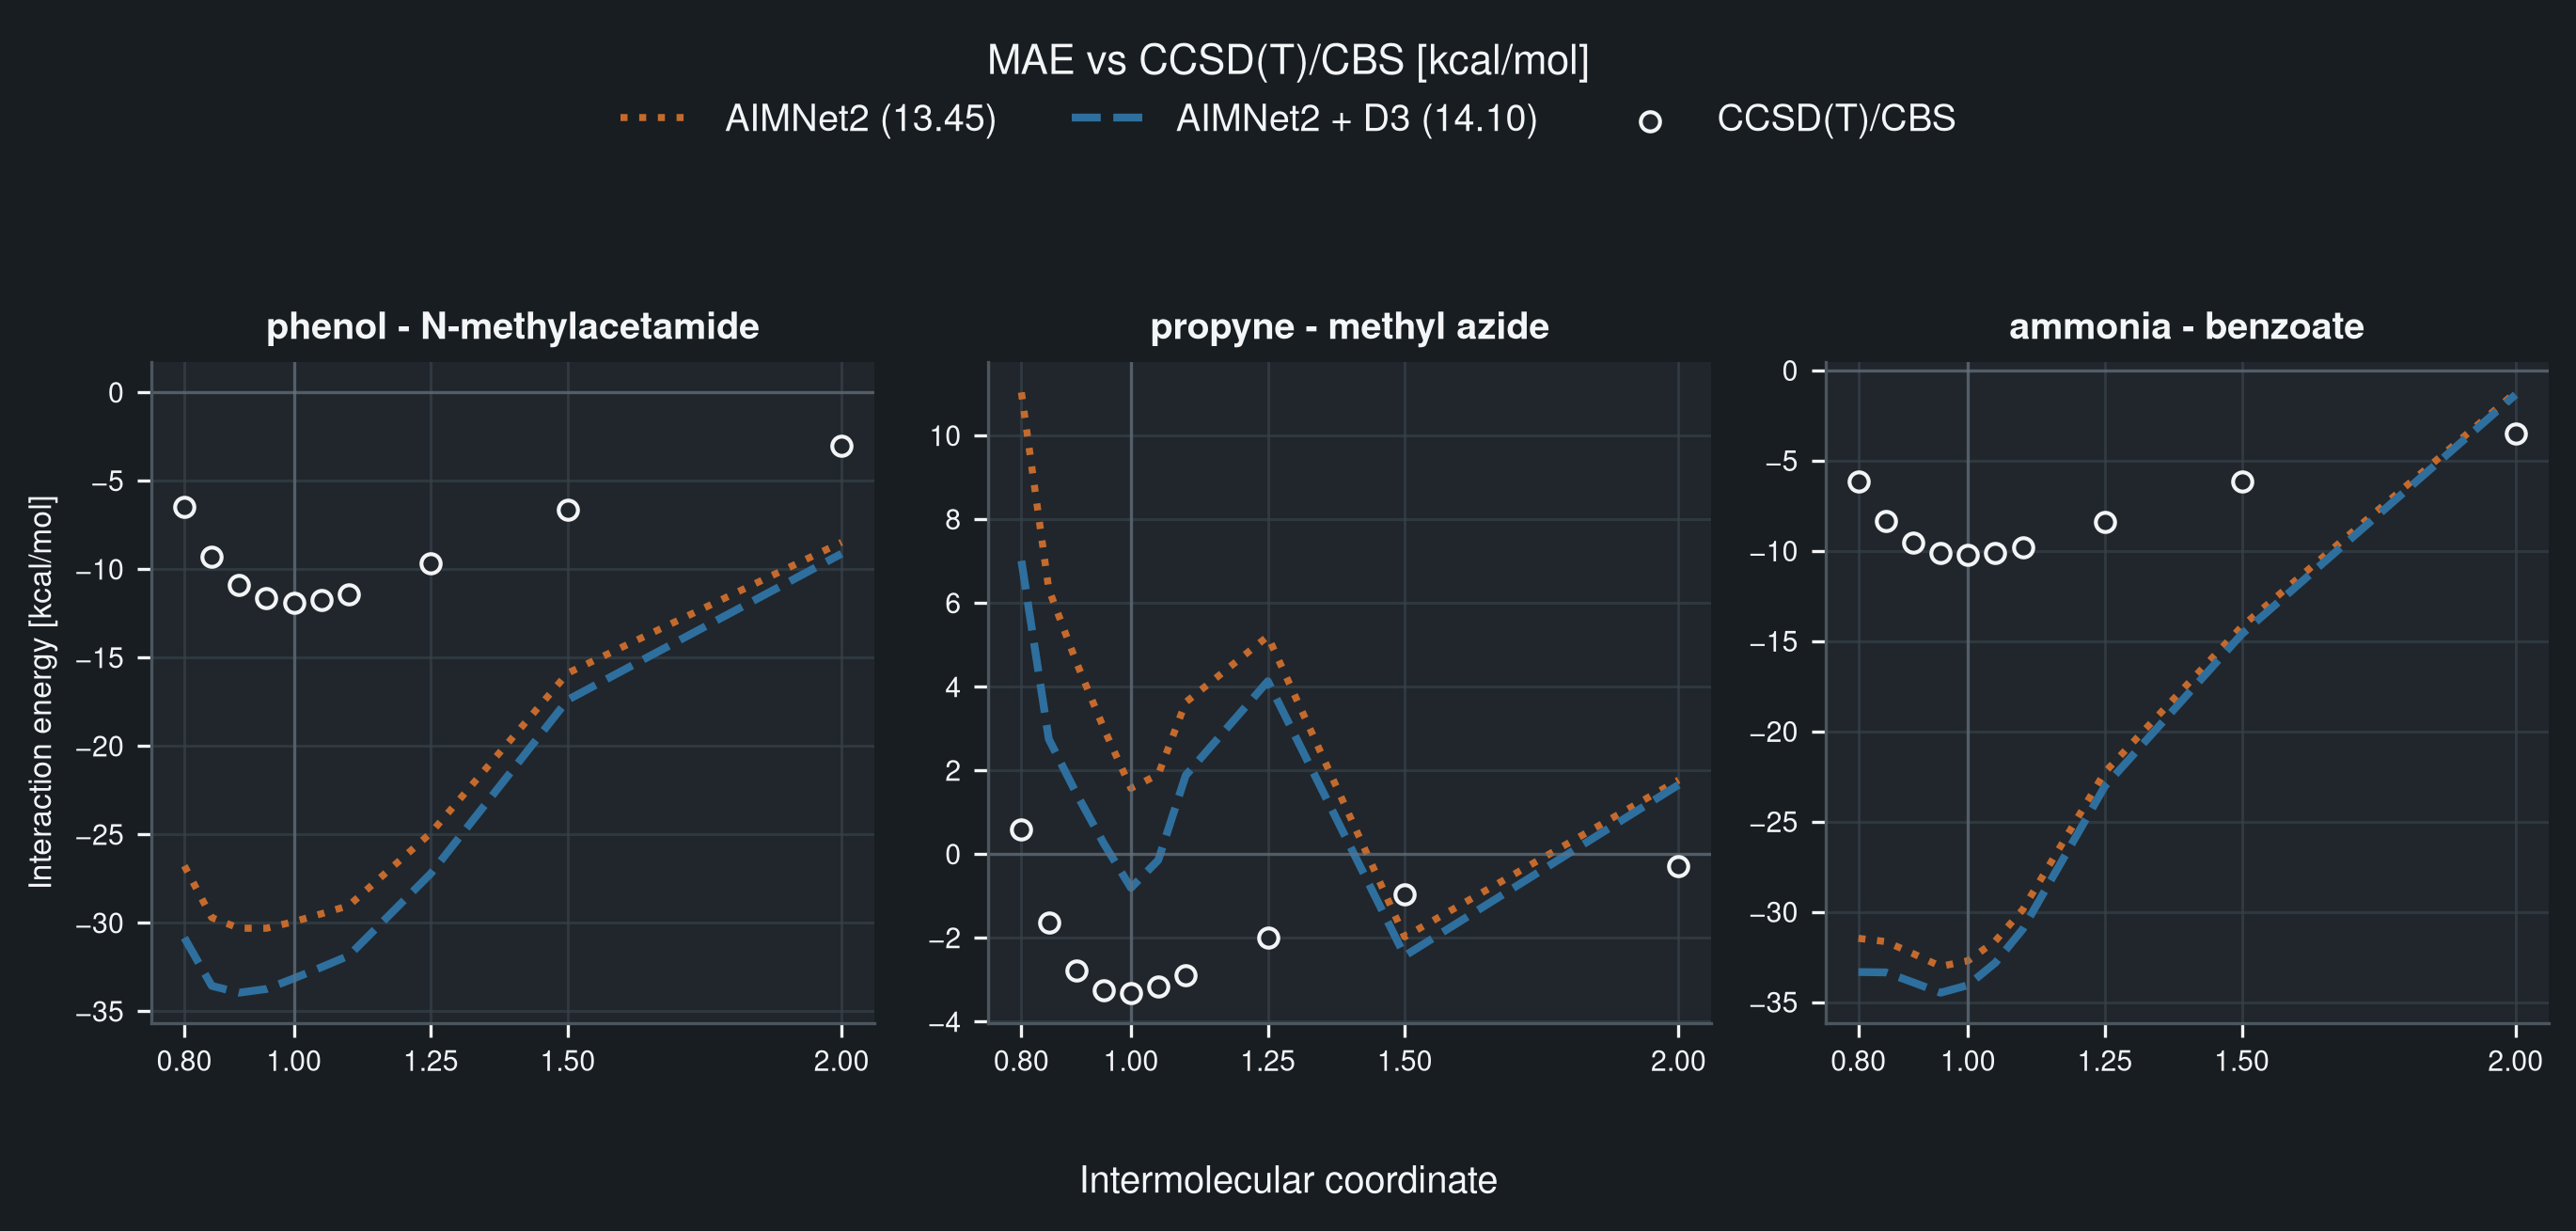

In [18]:
# Plot the effect of adding D3; the legend reports each route's MAE.
helpers.plot_nci_interaction_curves(
    d3_curves,
    nci_references,
    components=("aimnet_base", "base_d3"),
)

### Pass predicted charges between ordered steps

A `PipelineModelWrapper` organizes models into groups:

- `steps` inside one `PipelineGroup` run in order, so a later model can consume an earlier output.
- `groups` keep independent contributions and their derivative strategy separate.
- the pipeline sums energy and other additive outputs across the groups.

In the first group below, AIMNet2 predicts atomic `charges`. `wire={"charges": "partial_charges"}` writes that tensor onto the `Batch` under the input name required by the Coulomb step.

`helpers.DirectCoulombAdapter` is a course helper for finite, nonperiodic $1/r$ electrostatics. It uses those charges for atom pairs within cutoff and returns energy and forces through Toolkit's model interface.
Toolkit's built-in Ewald and PME wrappers target periodic cells. These isolated NCI complexes use the finite adapter above. We use the same 15 Å cutoff as D3, so the pipeline can share one finite neighbor range.

`use_autograd=True` sums the AIMNet2 and Coulomb energies first, then computes forces from the group energy. The derivative therefore includes the dependence of the Coulomb energy on AIMNet2's predicted charges. D3 stays in its own independent group.

> <span aria-label="ALCHEMI Toolkit API" class="alchemi-api-label">&lt;/&gt;&nbsp; API</span>
>
> `PipelineStep(aimnet, wire={"charges": "partial_charges"})`
>
> **Input:** AIMNet2's predicted `charges`  
> **Effect:** writes `partial_charges` for the following Coulomb step

In [ ]:
# Construct the finite, nonperiodic Coulomb term on the same device.
coulomb = helpers.DirectCoulombAdapter(
    cutoff=15.0,  # Match D3's finite neighbor range [Å]
)
coulomb.to(device)
coulomb.eval()
coulomb.set_config("active_outputs", {"energy"})

In [20]:
# Wire AIMNet2 charges into Coulomb's partial_charges input.
charge_step = PipelineStep(aimnet, wire={"charges": "partial_charges"})
charge_group = PipelineGroup(
    steps=[charge_step, coulomb],
    use_autograd=True,  # Differentiate the summed charge-dependent energy.
)
dispersion_group = PipelineGroup(steps=[d3], use_autograd=False)

interaction_model = PipelineModelWrapper(
    groups=[charge_group, dispersion_group],
    neighbor_adaptation="always",
)
interaction_model.to(device)
interaction_model.eval()
interaction_model.set_config("active_outputs", {"energy", "charges"})

In [21]:
# Inspect the public interface exposed by the composed model.
print("required batch inputs:", interaction_model.input_data())
print("active outputs:", interaction_model.model_config.active_outputs)

required batch inputs: {'atomic_numbers', 'positions', 'charge', 'neighbor_matrix', 'partial_charges', 'num_neighbors'}
active outputs: {'energy', 'charges'}


In [22]:
# Give the complete route its own Batch clone and shared source neighbors.
complete_batch = nci_scan_batch.clone()
compute_neighbors(
    complete_batch,
    config=interaction_model.model_config.neighbor_config,
)
# One forward call returns the composed energy and AIMNet2 atomic charges.
complete_output = interaction_model(complete_batch)

In [23]:
# Reshape the complete-model output into [scan points, AB/A/B].
complete_by_scan = complete_output["energy"].reshape(-1, 3)
complete_interactions = complete_by_scan[:, 0] - complete_by_scan[:, 1]
complete_interactions = complete_interactions - complete_by_scan[:, 2]
complete_interactions = complete_interactions * mol / kcal
complete_interactions = complete_interactions.detach().cpu()

computed_curves = d3_curves.copy()
computed_curves["complete"] = complete_interactions.numpy()


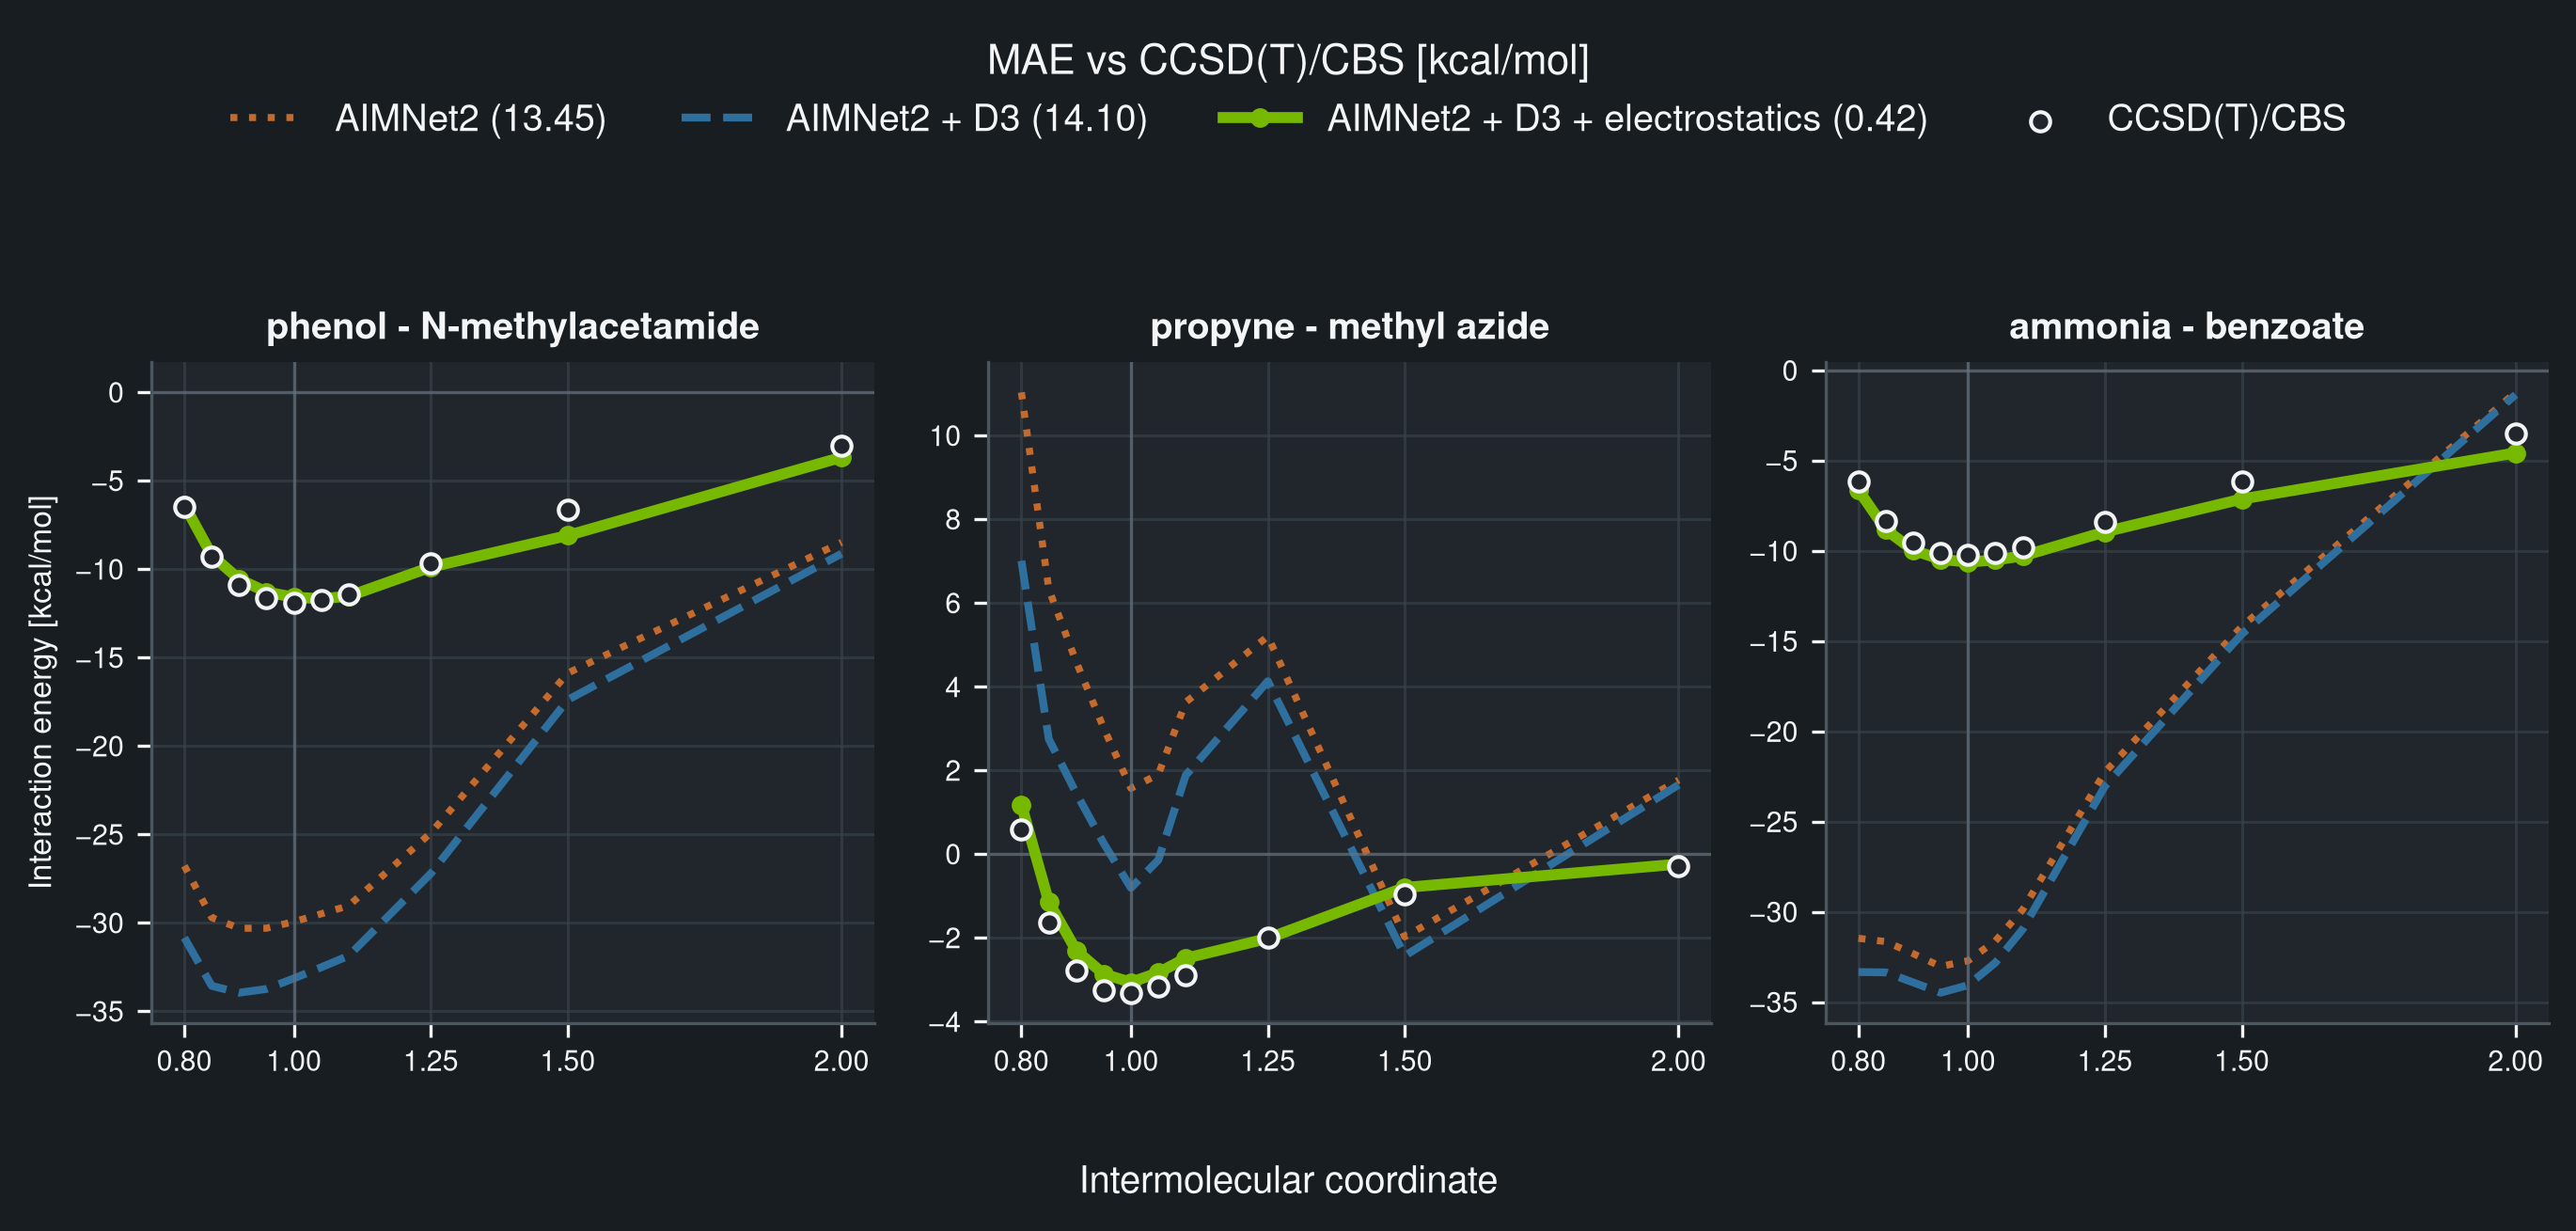

In [ ]:
# Compare all three computed model variants with CCSD(T)/CBS; legend values are MAEs.
helpers.plot_nci_interaction_curves(
    computed_curves,
    nci_references,
    components=("aimnet_base", "base_d3", "complete"),
)

### Evaluate accuracy across 205 complexes

The three scans above show how D3 and electrostatics change the interaction curves. For a broader accuracy check, evaluate the complete model across NCIA250.

NCIA250 contains 250 equilibrium complexes. The pinned AIMNet2 checkpoint does not support Ar, He, Kr, Ne, or Xe, so the loader keeps the remaining 205 complexes. It handles archive parsing and this element filtering behind the scenes.

Each interaction contributes consecutive `AB`, `A`, and `B` structures, so one `Batch` holds 615 structures for one model call.

In [ ]:
# Load the 205 supported interactions and their CCSD(T)/CBS references.
ncia_atoms, ncia_references = helpers.load_supported_ncia250()

# Convert each structure before packing all 615 on the selected device.
ncia_data = [
    AtomicData.from_atoms(atoms, device=device)
    for atoms in ncia_atoms
]
ncia_batch = Batch.from_data_list(ncia_data, device=device)

In [26]:
# Build the complete model's neighbors for all 615 structures.
full_model_batch = ncia_batch.clone()
compute_neighbors(
    full_model_batch,
    config=interaction_model.model_config.neighbor_config,
)

# One forward call evaluates every structure in the Batch.
full_output = interaction_model(full_model_batch)
structure_energies_ev = full_output["energy"].squeeze(-1)

In [27]:
# Reshape the 615 outputs into [interactions, AB/A/B].
energies_by_interaction = structure_energies_ev.reshape(-1, 3)
interaction_energies_ev = energies_by_interaction[:, 0] - energies_by_interaction[:, 1]
interaction_energies_ev = interaction_energies_ev - energies_by_interaction[:, 2]

# Convert the 205 interaction energies from eV to kcal/mol.
predicted_interactions = interaction_energies_ev * mol / kcal
predicted_interactions = predicted_interactions.detach().cpu()

#### Try it: measure accuracy across 205 complexes

> ✏️ **TRY IT**
>
> The previous cell produced one interaction energy for each supported complex. Complete exactly two lines in the next cell:
>
> 1. select the 205 CCSD(T)/CBS reference interaction energies; and
> 2. average the absolute error of the 205 model predictions.
>
> **Success:** the check prints one MAE in kcal/mol.

In [28]:
# TODO 1: select the 205 CCSD(T)/CBS interaction energies.
reference_energies = None

# TODO 2: average the absolute prediction error [kcal/mol].
mae_kcal_mol = None

if mae_kcal_mol is None:
    print("Complete the two TODO lines, then run this check again.")
else:
    print(f"MAE vs CCSD(T)/CBS: {float(mae_kcal_mol):.2f} kcal/mol")

Complete the two TODO lines, then run this check again.


> ✅ **SAMPLE SOLUTION**

<details>
<summary><strong>Open the sample solution</strong></summary>

```python
reference_energies = torch.from_numpy(
    ncia_references["ccsd_t_cbs_kcal_mol"].to_numpy()
)
mae_kcal_mol = (
    predicted_interactions - reference_energies
).abs().mean()
```

The subtraction produces one prediction error for each of the 205 complexes. Taking the absolute value and then the mean gives one model-accuracy result for the full supported set.

</details>

**🔗 Learn more in Toolkit docs**

- [Composable model example](https://nvidia.github.io/nvalchemi-toolkit/examples/advanced/07_composable_model_composition.html) - Build independent and dependent model groups.
- [D3 dispersion examples](https://nvidia.github.io/nvalchemi-toolkit-ops/examples/dispersion/index.html) - Explore batched GPU D3 energy and force calculations.

### ⚡ Power User: Does D3 still matter after electrostatics?

*Open this optional block to practice composing one new route from terms already used above.*

The complete route contains AIMNet2, electrostatics, and D3. Build a route with AIMNet2 and Coulomb, evaluate the same 90 structures, and compare its MAE with the complete route. The difference measures D3's value after electrostatics is already present.

#### Try it: compose the comparison route

> ✏️ **TRY IT**
>
> Fill only the two assignments in the next cell:
>
> 1. wrap AIMNet2 in `PipelineStep(...)` and wire `charges` to `partial_charges`;
> 2. put that step before `coulomb` in `comparison_steps`.
>
> **Hints:** use `{"charges": "partial_charges"}`. The supplied wrapper requests energy only, so its group uses `use_autograd=False`.
>
> Run the supplied evaluation and plot cells after filling the two lines.
>
> **Success:** the plot reports an MAE for AIMNet2 + electrostatics and for the complete route.

In [ ]:
# TODO 1: wire AIMNet2 charges to Coulomb's input name.
aimnet_charge_step = ...

# TODO 2: preserve the order AIMNet2 → Coulomb.
comparison_steps = ...

comparison_group = PipelineGroup(
    steps=comparison_steps,
    use_autograd=False,
)
aimnet_coulomb = PipelineModelWrapper(
    groups=[comparison_group],
    neighbor_adaptation="always",
)
aimnet_coulomb.to(device)
aimnet_coulomb.eval()
aimnet_coulomb.set_config("active_outputs", {"energy"})

In [ ]:
# Evaluate the same 90 AB/A/B structures with AIMNet2 plus Coulomb.
aimnet_coulomb_batch = nci_scan_batch.clone()
compute_neighbors(
    aimnet_coulomb_batch,
    config=aimnet_coulomb.model_config.neighbor_config,
)
aimnet_coulomb_output = aimnet_coulomb(aimnet_coulomb_batch)

# Reshape to [scan points, AB/A/B] and calculate interaction energies.
aimnet_coulomb_by_scan = aimnet_coulomb_output["energy"].reshape(-1, 3)
aimnet_coulomb_interactions = aimnet_coulomb_by_scan[:, 0] - aimnet_coulomb_by_scan[:, 1]
aimnet_coulomb_interactions = aimnet_coulomb_interactions - aimnet_coulomb_by_scan[:, 2]
aimnet_coulomb_interactions = aimnet_coulomb_interactions * mol / kcal
aimnet_coulomb_interactions = aimnet_coulomb_interactions.detach().cpu()

d3_value_curves = nci_references.drop(columns="ccsd_t_cbs_kcal_mol").copy()
d3_value_curves["aimnet_coulomb"] = aimnet_coulomb_interactions.numpy()
d3_value_curves["complete"] = computed_curves["complete"]

In [ ]:
# Read D3's effect from the two MAEs in the legend.
helpers.plot_nci_interaction_curves(
    d3_value_curves,
    nci_references,
    components=("aimnet_coulomb", "complete"),
)

> ✅ **SAMPLE SOLUTION**

<details>
<summary><strong>Open the sample solution</strong></summary>

```python
aimnet_charge_step = PipelineStep(
    aimnet,
    wire={"charges": "partial_charges"},
)
comparison_steps = [aimnet_charge_step, coulomb]
```

The first line transfers AIMNet2's predicted atomic charges to the input name expected by Coulomb. The second line fixes the execution order inside one `PipelineGroup`.

With the pinned checkpoint and these 30 scan points, the plot reports about `2.03 kcal/mol` MAE for AIMNet2 + electrostatics and `0.34 kcal/mol` for the complete route. D3 still contributes strongly after electrostatics is present.

</details>

Docs: [Composable model example](https://nvidia.github.io/nvalchemi-toolkit/examples/advanced/07_composable_model_composition.html) · [AIMNet2 electrostatics pipeline](https://nvidia.github.io/nvalchemi-toolkit/examples/advanced/08_aimnet2_ewald_pipeline.html)

<hr class="alchemi-section-divider" aria-hidden="true" style="border:0;border-top:1px solid #D6D9D4;margin:2.4rem 0 1rem;">

## 3 · Run molecular dynamics

<img src="assets/course-roadmap-module02-dynamics.svg" alt="ALCHEMI Core roadmap with Run dynamics highlighted in Module 02" style="display:block;box-sizing:border-box;width:100%;max-width:920px;height:auto;margin:0.75rem 0 0.5rem;">

Toolkit dynamics accepts the same model interface used for the interaction curves. We will first pass the complete model to `NVTLangevin` and run a vanilla trajectory.

The simulation reuses the three equilibrium complexes from the interaction scans.

### Build the dynamics `Batch`

Start from the equilibrium geometry of each NCI scan. Convert the three structures to `AtomicData`, then pack them into one `Batch` so `NVTLangevin` can advance them together.

In [ ]:
# Select one equilibrium structure and its fragment boundary per complex.
md_labels, md_structures, fragment_a_sizes = helpers.equilibrium_nci_complexes(
    nci_atoms,
    nci_rows,
)

In [ ]:
# Convert each structure to AtomicData with the fields dynamics updates.
md_records = []
for structure in md_structures:
    record = AtomicData.from_atoms(structure, device=device)
    system_energy = torch.zeros((1, 1), device=device)  # [systems, 1]
    atomic_forces = torch.zeros_like(record.positions)  # [atoms, 3]

    record.add_system_property("energy", system_energy)
    record.add_node_property("forces", atomic_forces)
    md_records.append(record)

# Pack the three systems into one dynamics Batch.
md_start = Batch.from_data_list(md_records, device=device)

### Set up a plain Langevin trajectory

`NVTLangevin` integrates positions and velocities while a Langevin thermostat exchanges energy with each complex. This run uses:

- `temperature = 1,000 K` for a hot molecular stress test;
- `dt = 1.0 fs` for each integration step;
- `friction = 0.002 fs⁻¹`, corresponding to a 500 fs thermostat damping time;
- `n_steps = 3,000`, giving a 3.0 ps trajectory; and
- a fixed random seed so the later biased run can use the same velocities and noise sequence.

> <span aria-label="ALCHEMI Toolkit API" class="alchemi-api-label">&lt;/&gt;&nbsp; API</span>
>
> `NVTLangevin(model=..., dt=..., temperature=..., friction=..., n_steps=...)`
>
> **Input:** one Toolkit model and the thermostat controls above  
> **Returns:** a dynamics object that advances the complete `Batch`

`HostMemory` copies each saved system to CPU as snapshots are written. `capacity` sets the maximum number of systems it can hold, so one saved state of this three-system `Batch` uses three slots. An early stop leaves part of that limit unused.

### Prepare forces and velocities

The interaction curves used energies and charges. Molecular dynamics also needs a force vector for every atom, so first enable forces for each model component.

Next, initialize one reproducible velocity sample. `initialize_velocities` accepts one target temperature per system and writes the sampled velocities into the `Batch` in place.

> <span aria-label="ALCHEMI Toolkit API" class="alchemi-api-label">&lt;/&gt;&nbsp; API</span>
>
> `initialize_velocities(velocities=..., masses=..., temperature=..., batch_idx=..., random_seed=...)`
>
> **Input:** velocities, one mass and system index per atom, one target temperature per system, and a seed  
> **Effect:** samples Maxwell-Boltzmann velocities, removes center-of-mass drift, and rescales each system to its target temperature

In [ ]:
# Dynamics needs system energies and atomic forces; charges still feed Coulomb.
aimnet.set_config("active_outputs", {"energy", "forces", "charges"})
d3.set_config("active_outputs", {"energy", "forces"})
coulomb.set_config("active_outputs", {"energy", "forces"})
interaction_model.set_config("active_outputs", {"energy", "forces", "charges"})

In [46]:
TEMPERATURE_K = 1000.0       # Thermostat target [K]
MD_TIMESTEP_FS = 1.0         # Integration timestep [fs]
MD_FRICTION_PER_FS = 0.002   # Langevin friction [fs⁻¹]
MD_STEPS = 3000              # 3.0 ps total trajectory
MD_RANDOM_SEED = 49          # Reproducible velocity and noise samples
SNAPSHOT_EVERY = 20          # Save every 20 integration steps

In [ ]:
# torch.full creates one target-temperature value for each system.
target_temperature = torch.full(
    (md_start.num_graphs,),          # Output shape: [systems]
    TEMPERATURE_K,                   # Fill every entry with 1000 K
    device=device,                   # Keep it with the Batch tensors
    dtype=md_start.positions.dtype,  # Match the position precision
)

`target_temperature` now holds one value per system. The next cell passes that tensor with each atom's mass and system index to `initialize_velocities`, which updates `md_start.velocities` in place. The following cell checks the realized temperature of each system.

In [ ]:
# Write one seeded thermal sample into the [atoms, 3] velocity tensor.
atom_masses = md_start.atomic_masses.reshape(-1)  # One mass per atom
atom_owners = md_start.batch_idx.int()            # System index for each atom

initialize_velocities(
    velocities=md_start.velocities,  # Updated in place
    masses=atom_masses,
    temperature=target_temperature,  # One target per system
    batch_idx=atom_owners,
    random_seed=MD_RANDOM_SEED,
)

In [ ]:
# T_s = 2 K_s / (3 N_s k_B), evaluated independently for each system.
initial_temperatures = helpers.system_temperatures(md_start)
print("initial temperatures [K]:", initial_temperatures.tolist())

In [ ]:
# HostMemory needs an upper bound: t = 0 plus the scheduled snapshots.
saved_time_points = 1 + len(range(0, MD_STEPS, SNAPSHOT_EVERY))
plain_store = HostMemory(capacity=saved_time_points * md_start.num_graphs)

# Build the vanilla 3.0 ps Langevin simulation.
plain_nvt = NVTLangevin(
    model=interaction_model,
    dt=MD_TIMESTEP_FS,
    temperature=TEMPERATURE_K,
    friction=MD_FRICTION_PER_FS,
    random_seed=MD_RANDOM_SEED,
    n_steps=MD_STEPS,
)

### Run a vanilla trajectory

A **hook** attaches an action to a named point in the dynamics loop. Hooks can update model data, modify coordinates, energies, or forces, watch for numerical problems, and record trajectory frames. The dynamics algorithm stays in charge of when each action runs.

> <span aria-label="ALCHEMI Toolkit API" class="alchemi-api-label">&lt;/&gt;&nbsp; API</span>
>
> `BaseDynamics.register_hook(hook, stage=None)`
>
> **Input:** a hook and an optional stage override  
> **Effect:** registers the hook at its configured or supplied dynamics stage

`interaction_model.make_neighbor_hooks()` returns the model-owned neighbor hooks already configured for `BEFORE_COMPUTE`. Register them once, and Toolkit keeps each term's neighbor data current as positions change. `SnapshotHook` saves all three systems every 20 steps, while the initialized state is stored once as \(t=0\).

Langevin first updates velocities using the force at the starting coordinates. The batch currently contains placeholder zeros, so `compute_neighbors(...)` and `compute(...)` evaluate the starting force before `run(...)`.

In [ ]:
# Clone the initialized state and save it as t = 0.
plain_start = md_start.clone()
plain_store.write(plain_start)

# Register the model-owned neighbor updates.
for neighbor_hook in interaction_model.make_neighbor_hooks():
    plain_nvt.register_hook(neighbor_hook)

# Save all three systems at the selected interval.
plain_snapshot_hook = SnapshotHook(
    plain_store,
    frequency=SNAPSHOT_EVERY,
)
plain_nvt.register_hook(plain_snapshot_hook)

In [ ]:
# Build neighbor data, then fill the starting energy and forces in place.
compute_neighbors(
    plain_start,
    config=interaction_model.model_config.neighbor_config,
)
plain_nvt.compute(plain_start)

In [ ]:
# Run the vanilla 3.0 ps trajectory.
plain_result = plain_nvt.run(plain_start)

# HostMemory saved three system records at each time point.
saved_plain_time_points = len(plain_store) // md_start.num_graphs
print("saved MD time points:", saved_plain_time_points)

### Keep a weak complex together during MD

<img src="assets/course-roadmap-module02-hooks.svg" alt="ALCHEMI Core roadmap with Modify with hooks highlighted in Module 02" style="display:block;box-sizing:border-box;width:100%;max-width:920px;height:auto;margin:0.75rem 0 0.5rem;">

The vanilla run uses the composed model directly. Intermolecular binding is weak enough that a hot trajectory can carry the two fragments apart. Some simulations instead need the complex to remain near its starting separation.

A hook adds that control at a named point in the dynamics step. Every hook has a `stage`, a `frequency`, and a `__call__(context, stage)` action. The live state is available as `context.batch`. Toolkit also provides hooks for snapshots, logging, NaN detection, energy-drift monitoring, force clamping, and periodic wrapping.

Here `BiasedPotentialHook` restrains the mass-weighted center-of-mass separation:

$$
R = \left\lVert \mathbf{r}_{\mathrm{COM},B} - \mathbf{r}_{\mathrm{COM},A} \right\rVert,
\qquad
\mathbf{r}_{\mathrm{COM}} =
\frac{\sum_i m_i \mathbf{r}_i}{\sum_i m_i}.
$$

The initial separation is $R_0$. The harmonic bias is

$$
U_{\mathrm{bias}}(R) = \frac{1}{2}k(R-R_0)^2,
\qquad
\left|F_{\mathrm{bias}}(R)\right| = k\left|R-R_0\right|.
$$

> <span aria-label="ALCHEMI Toolkit API" class="alchemi-api-label">&lt;/&gt;&nbsp; API</span>
>
> `BiasedPotentialHook(fragment_restraint, stage=DynamicsStage.AFTER_COMPUTE)`
>
> **Input:** a callback returning one bias energy per system and one bias force per atom  
> **Effect:** adds those values to the model energy and forces before integration continues

The next cell measures one $R_0$ per complex. Then the callback uses $k=10\ \mathrm{eV\,\AA^{-2}}$, a stiff tutorial restraint chosen to make the 3 ps comparison easy to see.

In [ ]:
# Measure one initial fragment COM separation R0 [Å] per complex.
reference_separations = helpers.fragment_com_separations(
    md_start,
    fragment_a_sizes,
)

In [ ]:
# Print one directly readable value for each complex.
for label, distance in zip(md_labels, reference_separations, strict=True):
    print(f"{label}: R0 = {distance.item():.3f} Å")

In [ ]:
# k controls how strongly each fragment separation returns to R0 [eV/Å²].
RESTRAINT_EV_PER_A2 = 10.0


def fragment_restraint(batch):
    """Return bias energy [systems, 1] and bias forces [atoms, 3]."""
    bias_energy, bias_forces = helpers.fragment_com_harmonic_bias(
        batch,
        fragment_a_sizes,
        reference_separations,
        RESTRAINT_EV_PER_A2,
    )
    return bias_energy, bias_forces

In [ ]:
# Allocate storage and match every plain-MD control.
biased_store = HostMemory(capacity=saved_time_points * md_start.num_graphs)
biased_nvt = NVTLangevin(
    model=interaction_model,          # Same composed potential
    dt=MD_TIMESTEP_FS,                # 1.0 fs
    temperature=TEMPERATURE_K,        # 1,000 K
    friction=MD_FRICTION_PER_FS,      # 0.002 fs⁻¹
    random_seed=MD_RANDOM_SEED,       # 49
    n_steps=MD_STEPS,                 # 3,000 steps = 3.0 ps
)

In [ ]:
# Clone the same initialized positions and velocities, then save t = 0.
biased_start = md_start.clone()
biased_store.write(biased_start)

# Register fresh model-owned neighbor hooks for this dynamics object.
for neighbor_hook in interaction_model.make_neighbor_hooks():
    biased_nvt.register_hook(neighbor_hook)

In [ ]:
# Add the bias after each model force evaluation.
bias_hook = BiasedPotentialHook(
    fragment_restraint,
    stage=DynamicsStage.AFTER_COMPUTE,
)
biased_nvt.register_hook(bias_hook)

# Save the matched trajectory at the same interval.
biased_snapshot_hook = SnapshotHook(
    biased_store,
    frequency=SNAPSHOT_EVERY,
)
biased_nvt.register_hook(biased_snapshot_hook)

In [ ]:
# Fill the starting energy and forces, including the zero-at-R0 bias.
compute_neighbors(
    biased_start,
    config=interaction_model.model_config.neighbor_config,
)
biased_nvt.compute(biased_start)

In [ ]:
# Run the matched 3.0 ps trajectory with the bias hook active.
biased_result = biased_nvt.run(biased_start)
print("saved biased-MD time points:", len(biased_store) // md_start.num_graphs)

### Measure fragment separation over time

`SnapshotHook` saves each complex separately. Because the three complexes advance together, every three consecutive saved systems belong to the same MD time.

> <span aria-label="ALCHEMI Toolkit API" class="alchemi-api-label">&lt;/&gt;&nbsp; API</span>
>
> `saved_batch = plain_store.read()`
>
> **Input:** the snapshots accumulated in `HostMemory`  
> **Returns:** one `Batch` containing the saved systems in write order

The next cell rebuilds one three-complex `Batch` for each saved time. The analysis then evaluates the COM separation $R$ defined above for every complex and time point.

In [ ]:
# Rebuild one synchronized three-complex Batch for each saved MD time.
def regroup_saved_frames(store, systems_per_frame):
    saved_batch = store.read()
    saved_systems = saved_batch.to_data_list()
    frames = []

    for start in range(0, len(saved_systems), systems_per_frame):
        # Consecutive records were written during the same snapshot call.
        systems_at_time = saved_systems[start : start + systems_per_frame]
        frame = Batch.from_data_list(
            systems_at_time,
            device=saved_batch.device,
        )
        frames.append(frame)

    return frames

In [ ]:
# Regroup both stores with the same three-system frame layout.
systems_per_frame = md_start.num_graphs
plain_md_frames = regroup_saved_frames(plain_store, systems_per_frame)
biased_md_frames = regroup_saved_frames(biased_store, systems_per_frame)

print("saved time points:", len(plain_md_frames))

#### Calculate fragment separation

Each saved frame contains the same three complexes. `fragment_a_sizes` marks the A/B atom boundary in each complex. The course helper applies the COM equation shown above and returns one separation $R$ per complex in Å.

In [ ]:
# Each helper call returns the three COM separations in one saved frame [Å].
plain_separation_rows = [
    helpers.fragment_com_separations(frame, fragment_a_sizes)
    for frame in plain_md_frames
]
biased_separation_rows = [
    helpers.fragment_com_separations(frame, fragment_a_sizes)
    for frame in biased_md_frames
]

# Stack saved times into tensors with shape [time points, complexes].
plain_separation_tensor = torch.stack(plain_separation_rows)
biased_separation_tensor = torch.stack(biased_separation_rows)

In [ ]:
# Move the [time points, complexes] tensors to CPU before list conversion.
plain_separation_tensor = plain_separation_tensor.cpu()
biased_separation_tensor = biased_separation_tensor.cpu()

print("separation tensor shape:", tuple(plain_separation_tensor.shape))

In [ ]:
# Assign each tensor column to its complex label for plotting.
plain_separations = {}
biased_separations = {}

for index, label in enumerate(md_labels):
    plain_separations[label] = plain_separation_tensor[:, index].tolist()
    biased_separations[label] = biased_separation_tensor[:, index].tolist()

print("separation series:", list(plain_separations))

In [ ]:
# HostMemory stores states, so rebuild their times from the snapshot schedule.
# The separately saved starting state is t = 0; hook step 0 follows one MD step.
time_fs = [0.0] + [
    (step + 1) * MD_TIMESTEP_FS
    for step in range(0, MD_STEPS, SNAPSHOT_EVERY)
]

In [ ]:
# max |R - R0| captures the largest separation excursion in each trajectory.
for complex_index, label in enumerate(md_labels):
    r0 = reference_separations[complex_index].item()
    plain_trace = plain_separation_tensor[:, complex_index]
    biased_trace = biased_separation_tensor[:, complex_index]

    plain_max_change = (plain_trace - r0).abs().max().item()
    biased_max_change = (biased_trace - r0).abs().max().item()

    print(f"{label}:")
    print(f"  vanilla MD max |R - R0|: {plain_max_change:.3f} Å")
    print(f"  with bias max |R - R0|: {biased_max_change:.3f} Å")

### Compare the matched trajectories

The printed $\max |R-R_0|$ gives one compact measure of the largest separation excursion in each run. The plot shows when that motion occurs across the full 3 ps trajectory.

The player shows vanilla MD in the top row and the matched run with `BiasedPotentialHook` in the bottom row. One play button and frame slider update all six structures.

Each card reports the current COM separation $R$. The biased row also reports the largest restraint-force magnitude reached so far:

$$
\max |F_{\mathrm{bias}}| = k\max |R-R_0|.
$$

Standard element colors show atom identity, and the dotted line joins the two fragment centers of mass.

In [ ]:
helpers.plot_fragment_separation_comparison(
    time_fs,
    plain_separations,
    biased_separations,
)

In [ ]:
# Build the six-view player from the saved vanilla and biased trajectories.
reference_distance_values = reference_separations.tolist()
bias_player = helpers.show_bias_comparison_player(
    plain_md_frames,
    biased_md_frames,
    labels=md_labels,
    fragment_sizes=fragment_a_sizes,
    reference_distances=reference_distance_values,
    force_constant_ev_per_a2=RESTRAINT_EV_PER_A2,
)

In [ ]:
display(bias_player)

In [ ]:
# Keep numerical failure separate from physical fragment separation.
plain_positions_are_finite = torch.isfinite(plain_result.positions).all().item()
biased_positions_are_finite = torch.isfinite(biased_result.positions).all().item()

if not (plain_positions_are_finite and biased_positions_are_finite):
    raise RuntimeError("A trajectory finished with non-finite coordinates")

print("trajectory check: both runs finished with finite positions")

### What changed

The two branches use the same model, starting coordinates, velocities, thermostat controls, and random sequence. The hook adds the harmonic fragment-separation energy and forces. The separation plot and six-card player show the resulting change for every complex.

> **Bottom line**
>
> `BiasedPotentialHook` changes the energy and forces seen by the integrator through a callback. The model and dynamics interfaces stay the same.

**🔗 Learn more in Toolkit docs**

- [Biased potential hook](https://nvidia.github.io/nvalchemi-toolkit/examples/advanced/01_biased_potential.html) - Add a bias through a dynamics hook.
- [NVT Langevin dynamics](https://nvidia.github.io/nvalchemi-toolkit/examples/basic/05_nvt_langevin.html) - Configure temperature, timestep, friction, and reproducible noise.
- [Dynamics hooks](https://nvidia.github.io/nvalchemi-toolkit/userguide/hooks.html) - Register operations at named workflow stages.

<hr class="alchemi-section-divider" aria-hidden="true" style="border:0;border-top:1px solid #D6D9D4;margin:2.4rem 0 1rem;">

### ⚡ Power User: debug a broken MD update with hooks

*Imagine you are developing an MD algorithm. The coordinates begin evolving in an unexpected way, and a few steps later the model returns NaNs.*


The first debugging task is to locate the exact step where the trajectory becomes invalid and preserve that state for inspection. Once you have the failing coordinates, you can examine what changed and look for a pattern.

This short experiment makes that workflow reproducible. A small custom hook injects a coordinate collision at a seeded step. `SnapshotHook` records the updated coordinates before the model call, and `NaNDetectorHook` stops at the first non-finite energy or force.

`fault → snapshot → neighbor update → model compute → NaN detector`

The 20-step run is long enough to show normal updates before the injected failure.

#### Read a custom hook

A Toolkit hook is any object with three public pieces:

- `stage` selects the point in the workflow where it runs.
- `frequency` selects how often the engine calls it.
- `__call__(context, stage)` reads or updates the current workflow state.

For dynamics, `context.batch` is the live `Batch` and `context.step_count` is the current step. `context.model` and `context.workflow` are available when a hook needs them. Hooks that own a file, logger, or profiler can also implement `__enter__` and `__exit__` for setup and cleanup around `run()`.

The custom class below runs at `AFTER_PRE_UPDATE`, after the integrator moves the coordinates and before the model evaluates them.

In [ ]:
class CoordinateCollisionFaultHook:
    """Create one reproducible coordinate collision for this debug run."""

    stage = DynamicsStage.AFTER_PRE_UPDATE
    frequency = 1

    def __init__(self, system, pair, seed, trigger_window):
        self.system = system
        self.pair = pair
        self.trigger_step = random.Random(seed).randint(*trigger_window)

    def __call__(self, context: DynamicsContext, stage):
        if context.step_count == self.trigger_step:
            # batch_ptr locates this system inside the packed atom rows.
            system_start = int(context.batch.batch_ptr[self.system])
            first, second = (
                system_start + local_index
                for local_index in self.pair
            )

            # This test hook edits coordinates without recording an autograd operation.
            with torch.no_grad():
                first_position = context.batch.positions[first]
                # Exact overlap imitates the coordinate-update bug.
                context.batch.positions[second].copy_(first_position)

In [ ]:
# Choose one system and local atom pair; the seed fixes a step in 12-18.
fault_hook = CoordinateCollisionFaultHook(
    system=1,
    pair=(0, 1),
    seed=23,
    trigger_window=(12, 18),
)

print("fault system:", md_labels[fault_hook.system])
print("local atom pair:", fault_hook.pair)
print("trigger step:", fault_hook.trigger_step)

#### Build the short debug workflow

This `NVTLangevin` instance runs at zero temperature and zero friction for 20 steps. The model already provides energy and forces from the preceding MD experiment. Here we create only a fresh trajectory store and a short integrator.

Its purpose is to advance the normal integration lifecycle far enough to reach the seeded fault. `HostMemory` reserves room for one saved state per system and step.

In [ ]:
# Reserve one pre-compute snapshot per system for at most 20 debug steps.
debug_store = HostMemory(capacity=20 * md_start.num_graphs)
# Reuse the 1.0 fs MD step; T=0 and friction=0 make the fault deterministic.
debug_nvt = NVTLangevin(
    model=interaction_model,
    dt=MD_TIMESTEP_FS,
    temperature=0.0,
    friction=0.0,
    random_seed=23,
    n_steps=20,
)

#### Register the diagnostic chain

The stages follow the data that we need to inspect:

1. The fault hook runs at `AFTER_PRE_UPDATE`, after coordinates move.
2. `SnapshotHook` runs next at the same stage and stores those coordinates before the model call. Hooks at one stage run in registration order.
3. The model's neighbor hooks run at `BEFORE_COMPUTE` and rebuild neighbor data for the changed coordinates.
4. `NaNDetectorHook` runs at `AFTER_COMPUTE`. It checks `energy` and `forces` with `torch.isfinite` and raises a `RuntimeError` containing the step, fields, counts, and affected system indices.

`NaNDetectorHook(extra_keys=[...])` can inspect additional batch tensors. Its `frequency` can reduce monitoring cost in a long production run.

In [ ]:
debug_nvt.register_hook(fault_hook)

debug_snapshot_hook = SnapshotHook(
    debug_store,
    stage=DynamicsStage.AFTER_PRE_UPDATE,
)
debug_nvt.register_hook(debug_snapshot_hook)

for neighbor_hook in interaction_model.make_neighbor_hooks():
    debug_nvt.register_hook(neighbor_hook)

nan_detector = NaNDetectorHook(stage=DynamicsStage.AFTER_COMPUTE)
debug_nvt.register_hook(nan_detector)

#### Run until the detector stops the trajectory

The integrator's first velocity update needs the force at the clean starting coordinates. We prepare the model inputs and call `compute(...)` once before `run(...)`.

The coordinate hook then creates the exact overlap at its selected step. The expected `RuntimeError` is the result of this debugging experiment, and its message reports the affected fields and systems. The following cell reads `HostMemory` directly and selects the saved system at that same step.

In [ ]:
debug_start = md_start.clone()
compute_neighbors(
    debug_start,
    config=interaction_model.model_config.neighbor_config,
)
debug_nvt.compute(debug_start)

try:
    debug_nvt.run(debug_start)
except RuntimeError as error:
    if not str(error).startswith("Non-finite values detected"):
        raise
    print(error)
else:
    raise RuntimeError("NaNDetectorHook did not detect the injected collision")

In [ ]:
# Records are ordered first by debug step, then by system.
debug_records = debug_store.read().to_data_list()
systems_per_step = md_start.num_graphs
captured_time_points = len(debug_records) // systems_per_step

# Jump to the trigger step, then select the affected system.
fault_record_index = (
    fault_hook.trigger_step * systems_per_step
    + fault_hook.system
)
faulty_system = debug_records[fault_record_index]

# The hook stores system-local atom indices in pair.
first, second = fault_hook.pair
fault_vector = faulty_system.positions[second] - faulty_system.positions[first]
captured_distance = torch.linalg.vector_norm(fault_vector).item()

# Finite positions plus zero pair distance identify the bad model input.
nonfinite_positions = (~torch.isfinite(faulty_system.positions)).sum().item()

print("captured time points:", captured_time_points)
print(f"faulty pair distance [Å]: {captured_distance:.3f}")
print("non-finite position values:", nonfinite_positions)

#### What the captured state shows

The saved coordinates remain finite and contain the injected $0.0\ \mathrm{\AA}$ pair. The next model call produces non-finite energy or forces, and `NaNDetectorHook` stops the run. `SnapshotHook` preserves the exact input state that caused the failure.

**🔗 Continue with Toolkit docs**

- [Safety and monitoring](https://nvidia.github.io/nvalchemi-toolkit/examples/intermediate/05_safety_and_monitoring.html) explains the built-in monitoring hooks.
- [`NaNDetectorHook` API](https://nvidia.github.io/nvalchemi-toolkit/modules/dynamics/generated/nvalchemi.dynamics.hooks.NaNDetectorHook.html) lists its configuration and detected fields.
- [Custom hook example](https://nvidia.github.io/nvalchemi-toolkit/examples/advanced/02_custom_hook.html) develops the extension pattern used here.

<hr class="alchemi-section-divider" aria-hidden="true" style="border:0;border-top:1px solid #D6D9D4;margin:2.4rem 0 1rem;">

### ⚡ Power User: implement Velocity Verlet with `BaseDynamics`

*Open this optional block when you want to add an integration rule while keeping Toolkit's model and hook lifecycle.*

Velocity Verlet advances each atom $i$ from step $n$ to $n+1$. Its position, velocity, force, and mass are $\mathbf r_i^n$, $\mathbf v_i^n$, $\mathbf F_i^n$, and $m_i$.

$$
\begin{aligned}
\mathbf v_i^{n+1/2}
  &= \mathbf v_i^n + \frac{\Delta t}{2}\frac{\mathbf F_i^n}{m_i}
  && \text{first half-kick} \\
\mathbf r_i^{n+1}
  &= \mathbf r_i^n + \Delta t\,\mathbf v_i^{n+1/2}
  && \text{position drift} \\
\mathbf F_i^{n+1}
  &= -\nabla_{\mathbf r_i} E(\mathbf r^{n+1})
  && \text{model evaluation} \\
\mathbf v_i^{n+1}
  &= \mathbf v_i^{n+1/2} + \frac{\Delta t}{2}\frac{\mathbf F_i^{n+1}}{m_i}
  && \text{second half-kick}
\end{aligned}
$$

#### Map the equations to Toolkit

One `BaseDynamics` step calls the three methods in this order:

1. `pre_update(batch)` applies the first half-kick with $\mathbf F^n$, then updates the positions.
2. `compute(batch)` evaluates the model at $\mathbf r^{n+1}$ and writes $\mathbf F^{n+1}$.
3. `post_update(batch)` applies the second half-kick with the new force.

`atomic_masses.reshape(-1, 1)` gives one mass per atom and broadcasts it across the three Cartesian components. Multiplying a timestep in femtoseconds by `ase.units.fs` converts it to the units used by these tensor updates.

`__needs_keys__ = {"forces"}` requires the model to return forces. `__provides_keys__ = {"positions", "velocities"}` declares the fields that this integrator updates.

#### Try it: translate Velocity Verlet into tensor updates

> ✏️ **TRY IT**
>
> Complete the three TODOs in `StudentVelocityVerlet`:
>
> 1. In `pre_update`, add $\frac{\Delta t}{2}\mathbf F^n/m$ to `batch.velocities`.
> 2. Still in `pre_update`, add $\Delta t\,\mathbf v^{n+1/2}$ to `batch.positions`.
> 3. In `post_update`, add $\frac{\Delta t}{2}\mathbf F^{n+1}/m$ to `batch.velocities`.
>
> `BaseDynamics` evaluates the model between the two methods. Run the next comparison with Toolkit's built-in `NVE` after filling the TODOs.
>
> **Success:** the printed position and velocity differences remain close to numerical precision across all four steps.

In [ ]:
from ase.units import fs as ASE_FS
from nvalchemi.dynamics import BaseDynamics


class StudentVelocityVerlet(BaseDynamics):
    __needs_keys__ = {"forces"}
    __provides_keys__ = {"positions", "velocities"}

    def __init__(self, model, dt, **kwargs):
        super().__init__(model=model, **kwargs)
        self.dt = dt * ASE_FS  # Convert femtoseconds to the update units.

    def pre_update(self, batch):
        masses = batch.atomic_masses.reshape(-1, 1)
        # Update the live trajectory state outside PyTorch's gradient graph.
        with torch.no_grad():
            # Δv = (Δt / 2) F(t) / m
            # TODO 1: update batch.velocities in place.

            # Δr = Δt v(t + Δt / 2)
            # TODO 2: update batch.positions in place.
            pass

    def post_update(self, batch):
        masses = batch.atomic_masses.reshape(-1, 1)
        # Apply the second state update with the refreshed model force.
        with torch.no_grad():
            # Δv = (Δt / 2) F(t + Δt) / m
            # TODO 3: update batch.velocities in place.
            pass

#### Compare each update with Toolkit's `NVE`

`NVE` is Toolkit's built-in Velocity Verlet integrator. The next four cells prepare identical state, construct both integrators, evaluate the shared starting force, and compare four paired `step(...)` updates.

Each output row reports the largest position and velocity difference after one update. Read the values directly to see how closely the two implementations agree.

In [ ]:
from nvalchemi.dynamics import NVE

VALIDATION_TIMESTEP_FS = 0.25  # Integration timestep [fs]
VALIDATION_STEPS = 4           # Number of paired updates

# Select one complex, then give each integrator an independent clone.
validation_start = md_start[1:2]
custom_batch = validation_start.clone()
toolkit_batch = validation_start.clone()

In [ ]:
# Construct both integrators with their own model-owned neighbor hooks.
custom_hooks = interaction_model.make_neighbor_hooks()
toolkit_hooks = interaction_model.make_neighbor_hooks()

custom_vv = StudentVelocityVerlet(
    interaction_model,
    dt=VALIDATION_TIMESTEP_FS,
    hooks=custom_hooks,
)
toolkit_nve = NVE(
    interaction_model,
    dt=VALIDATION_TIMESTEP_FS,
    hooks=toolkit_hooks,
)

In [ ]:
# Both first half-kicks must use F(t) at the same starting coordinates.
integrator_batches = [
    (custom_vv, custom_batch),
    (toolkit_nve, toolkit_batch),
]

for dynamics, batch in integrator_batches:
    compute_neighbors(
        batch,
        config=interaction_model.model_config.neighbor_config)
    dynamics.compute(batch)

In [ ]:
# Advance both public integrators once, then compare their updated states.
for step in range(1, VALIDATION_STEPS + 1):
    custom_vv.step(custom_batch)
    toolkit_nve.step(toolkit_batch)

    position_difference = custom_batch.positions - toolkit_batch.positions
    velocity_difference = custom_batch.velocities - toolkit_batch.velocities
    max_position_difference = position_difference.abs().max().item()
    max_velocity_difference = velocity_difference.abs().max().item()
    max_velocity_difference_ang_per_fs = max_velocity_difference * ASE_FS

    print(f"step: {step}")
    print(f"  max |Δr| [Å]: {max_position_difference:.3e}")
    print(f"  max |Δv| [Å/fs]: {max_velocity_difference_ang_per_fs:.3e}")

> ✅ **SAMPLE SOLUTION**

<details>
<summary><strong>Open the sample solution</strong></summary>

```python
class StudentVelocityVerlet(BaseDynamics):
    __needs_keys__ = {"forces"}
    __provides_keys__ = {"positions", "velocities"}

    def __init__(self, model, dt, **kwargs):
        super().__init__(model=model, **kwargs)
        self.dt = dt * ASE_FS

    def pre_update(self, batch):
        masses = batch.atomic_masses.reshape(-1, 1)
        with torch.no_grad():
            batch.velocities.add_(
                0.5 * self.dt * batch.forces / masses
            )
            batch.positions.add_(self.dt * batch.velocities)

    def post_update(self, batch):
        masses = batch.atomic_masses.reshape(-1, 1)
        with torch.no_grad():
            batch.velocities.add_(
                0.5 * self.dt * batch.forces / masses
            )
```

The first method sees $\mathbf F(t)$. The model call between the methods refreshes the force, so the second method sees $\mathbf F(t + \Delta t)$.

The comparison calls `step(...)` on both public integrators from the same initial state. Each step reports the largest coordinate difference `max |Δr|` in Å and velocity difference `max |Δv|` in Å/fs after one paired update. The printed values show how closely the learner's tensor updates reproduce Toolkit's built-in `NVE` across all four steps.

</details>

Docs: [Custom integrator example](https://nvidia.github.io/nvalchemi-toolkit/examples/advanced/05_custom_integrator.html) · [Integrator algorithms](https://nvidia.github.io/nvalchemi-toolkit/modules/dynamics/methods.html) · [NVE energy-conservation example](https://nvidia.github.io/nvalchemi-toolkit/examples/basic/04_nve_energy_conservation.html)

### Learn about Toolkit

Continue with three official examples that extend the main ideas in this module:

- [Composable model composition](https://nvidia.github.io/nvalchemi-toolkit/examples/advanced/07_composable_model_composition.html) - Build independent model terms and ordered property transfers with `PipelineModelWrapper`.
- [Custom hook](https://nvidia.github.io/nvalchemi-toolkit/examples/advanced/02_custom_hook.html) - Read workflow state and accumulate a structural observable at a chosen stage.
- [Custom integrator](https://nvidia.github.io/nvalchemi-toolkit/examples/advanced/05_custom_integrator.html) - Implement a new update rule with `BaseDynamics`.

## Module 02 recap

You composed AIMNet2, D3, and electrostatics through the Toolkit interface into one model. You passed that model directly to Langevin dynamics, then used `BiasedPotentialHook` to keep weak molecular complexes near their starting separation. The optional Power User blocks use the same APIs to diagnose a coordinate-update failure and implement a custom Velocity Verlet integrator.

Module 03 scales the same model into a multistage computational study with Toolkit.

**Next module:** [Module 03: Scale a study →](alchemi-core-03-scale-a-study.ipynb)